# Bivariate stochastic volatility: IBM and S&P 500
Research notebook by Jiayin Wang. See the repository README for data requirements and limitations.
Saved model outputs are retained from the supplied notebook. The included data-processing pipeline has been checked; the full estimation and MCMC workflow has not been rerun for this package.


In [ ]:
from pathlib import Path
import os
if (Path.cwd() / "notebooks").is_dir():
    os.chdir(Path.cwd() / "notebooks")
if not (Path.cwd().parent / "data" / "raw").is_dir():
    raise RuntimeError("Run this notebook from the repository root or notebooks directory.")
Path("../figures").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)


In [ ]:
# =========================
# 1. Basic Python utilities
# =========================
from pathlib import Path
from dataclasses import dataclass
from typing import NamedTuple

# =========================
# 2. Data processing
# =========================
import numpy as np
import pandas as pd

# =========================
# 3. Plotting
# =========================
import matplotlib.pyplot as plt

# =========================
# 4. Classical estimation
# =========================
from scipy.optimize import minimize
from scipy.linalg import solve_triangular

# =========================
# 5. Statistical diagnostics
# =========================
from statsmodels.stats.diagnostic import acorr_ljungbox

# =========================
# 6. JAX
# =========================
import jax
import jax.numpy as jnp
import jax.random as jr
import jax.scipy as jsp

from jax import lax, jit, vmap
#模型涉及协方差矩阵、log-likelihood、Cholesky decomposition 和 MCMC，使用 64-bit 会更稳。
jax.config.update("jax_enable_x64", True)


MODULE 1: READ AND PLOT DATA

In [3]:

# ============================================================
# 1. Read IBM daily data
# ============================================================

ibm_path = "../data/raw/ibm.csv"

ibm_raw = pd.read_csv(ibm_path)

ibm_raw["Date"] = pd.to_datetime(
    ibm_raw["Date"],
    errors="coerce"
)

ibm_raw["Adj Close"] = pd.to_numeric(
    ibm_raw["Adj Close"],
    errors="coerce"
)

ibm_raw = ibm_raw.dropna(
    subset=["Date", "Adj Close"]
).copy()

ibm_raw = ibm_raw.sort_values("Date")

# Keep the textbook sample period
ibm_raw = ibm_raw[
    (ibm_raw["Date"] >= "1962-01-01")
    & (ibm_raw["Date"] <= "2009-12-31")
].copy()

ibm_raw.head()

,Date,Open,High,Low,Close,Volume,Adj Close
0,1962-01-02,578.499734,578.499734,572.000241,572.000241,387200,2.300695
1,1962-01-03,572.000241,576.999736,572.000241,576.999736,288000,2.320804
2,1962-01-04,576.999736,576.999736,570.999742,571.250260,256000,2.297679
3,1962-01-05,570.500243,570.500243,558.999753,560.000253,363200,2.252429
4,1962-01-08,559.500003,559.500003,545.000267,549.500263,544000,2.210196


In [4]:
# ============================================================
# 2. Convert IBM daily prices to monthly prices
# ============================================================

ibm_raw["month"] = ibm_raw["Date"].dt.to_period("M")

ibm_monthly = (
    ibm_raw
    .groupby("month")
    .first()
)

ibm_monthly = ibm_monthly[
    ["Date", "Adj Close"]
].rename(
    columns={
        "Date": "ibm_date",
        "Adj Close": "ibm_P_t"
    }
)

display(ibm_monthly.head())
display(ibm_monthly.tail())

print("IBM monthly observations:", len(ibm_monthly))

,ibm_date,ibm_P_t
month,,
1962-01,1962-01-02,2.300695
1962-02,1962-02-01,2.230305
1962-03,1962-03-01,2.186360
1962-04,1962-04-02,2.113951
1962-05,1962-05-01,1.858506


,ibm_date,ibm_P_t
month,,
2009-08,2009-08-03,102.531200
2009-09,2009-09-01,100.234907
2009-10,2009-10-01,101.274277
2009-11,2009-11-02,103.559173
2009-12,2009-12-01,110.391706


IBM monthly observations: 576


In [5]:
# ============================================================
# 3. Read S&P 500 monthly data
# ============================================================

sp_path = "../data/raw/sp500_raw.xlsx"

sp_raw = pd.read_excel(
    sp_path,
    header=None,
    names=["date", "sp_P_t"]
)

sp_raw["sp_P_t"] = (
    sp_raw["sp_P_t"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace("\u2002", "", regex=False)
    .str.replace("\xa0", "", regex=False)
    .str.strip()
)

sp_raw["sp_P_t"] = pd.to_numeric(
    sp_raw["sp_P_t"],
    errors="coerce"
)

sp_raw["date"] = pd.to_datetime(
    sp_raw["date"],
    errors="coerce"
)

sp_raw = sp_raw.dropna(
    subset=["date", "sp_P_t"]
).copy()

sp_raw = sp_raw.sort_values("date")

sp_raw["month"] = sp_raw["date"].dt.to_period("M")

sp_monthly = sp_raw.set_index("month")[
    ["date", "sp_P_t"]
]

display(sp_monthly.head())
display(sp_monthly.tail())

print("S&P 500 monthly observations:", len(sp_monthly))

,date,sp_P_t
month,,
1962-01,1962-01-01,69.07
1962-02,1962-02-01,70.22
1962-03,1962-03-01,70.29
1962-04,1962-04-01,68.05
1962-05,1962-05-01,62.99


,date,sp_P_t
month,,
2009-08,2009-08-01,1009.73
2009-09,2009-09-01,1044.55
2009-10,2009-10-01,1067.66
2009-11,2009-11-01,1088.07
2009-12,2009-12-01,1110.38


S&P 500 monthly observations: 576


In [6]:
# ============================================================
# 4. Align the two monthly price series
# ============================================================

monthly = ibm_monthly.join(
    sp_monthly,
    how="inner"
)

monthly = monthly.rename(
    columns={
        "date": "sp_date"
    }
)

display(monthly.head())
display(monthly.tail())

print("Aligned monthly observations:", len(monthly))

,ibm_date,ibm_P_t,sp_date,sp_P_t
month,,,,
1962-01,1962-01-02,2.300695,1962-01-01,69.07
1962-02,1962-02-01,2.230305,1962-02-01,70.22
1962-03,1962-03-01,2.186360,1962-03-01,70.29
1962-04,1962-04-02,2.113951,1962-04-01,68.05
1962-05,1962-05-01,1.858506,1962-05-01,62.99


,ibm_date,ibm_P_t,sp_date,sp_P_t
month,,,,
2009-08,2009-08-03,102.531200,2009-08-01,1009.73
2009-09,2009-09-01,100.234907,2009-09-01,1044.55
2009-10,2009-10-01,101.274277,2009-10-01,1067.66
2009-11,2009-11-02,103.559173,2009-11-01,1088.07
2009-12,2009-12-01,110.391706,2009-12-01,1110.38


Aligned monthly observations: 576


In [7]:
# ============================================================
# 5. Calculate monthly percentage log returns
# ============================================================

monthly["log_ibm_P_t"] = np.log(
    monthly["ibm_P_t"]
)

monthly["log_sp_P_t"] = np.log(
    monthly["sp_P_t"]
)

returns = pd.DataFrame(index=monthly.index)

returns["r_ibm"] = (
    100 * monthly["log_ibm_P_t"].diff()
)

returns["r_sp"] = (
    100 * monthly["log_sp_P_t"].diff()
)

returns = returns.dropna()

display(returns.head())
display(returns.tail())

print("Return observations:", len(returns))
plot_dates = returns.index.to_timestamp()

,r_ibm,r_sp
month,,
1962-02,-3.107290,1.651269
1962-03,-1.990029,0.099637
1962-04,-3.367935,-3.238681
1962-05,-12.878577,-7.726675
1962-06,-18.216467,-12.425336


,r_ibm,r_sp
month,,
2009-08,13.438949,7.601510
2009-09,-2.265064,3.390320
2009-10,1.031595,2.188317
2009-11,2.231072,1.893615
2009-12,6.389184,2.029681


Return observations: 575


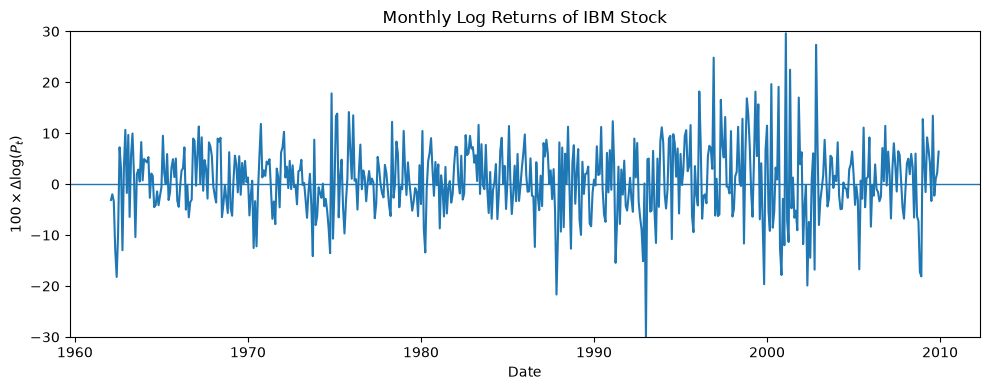

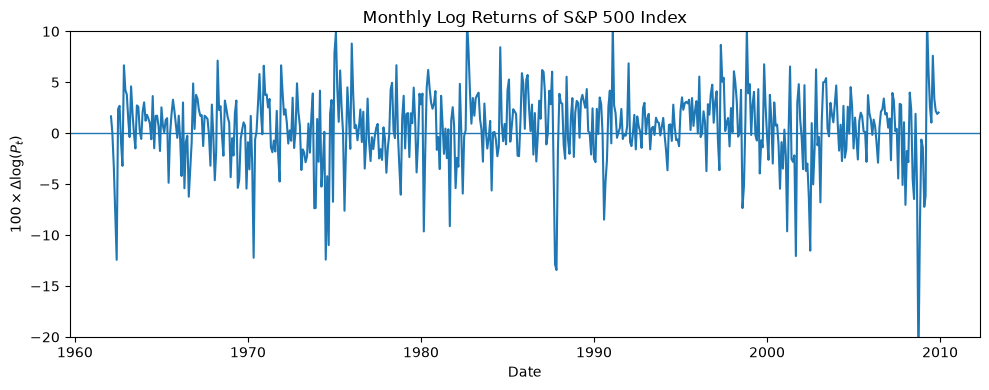

In [8]:
# ============================================================
# 6. Plot IBM monthly log returns
# ============================================================

plt.figure(figsize=(10, 4))

plt.plot(
    plot_dates,
    returns["r_ibm"]
)

plt.axhline(
    0,
    linewidth=1
)

plt.ylim(
    -30,
    30
)

plt.title(
    "Monthly Log Returns of IBM Stock"
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    r"$100 \times \Delta \log(P_t)$"
)

plt.tight_layout()

plt.savefig(
    "../figures/fig_12_7a_ibm_log_returns.png",
    dpi=300
)

plt.show()
# ============================================================
# 7. Plot S&P 500 monthly log returns
# ============================================================

plt.figure(figsize=(10, 4))

plt.plot(
    plot_dates,
    returns["r_sp"]
)

plt.axhline(
    0,
    linewidth=1
)

plt.ylim(
    -20,
    10
)

plt.title(
    "Monthly Log Returns of S&P 500 Index"
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    r"$100 \times \Delta \log(P_t)$"
)

plt.tight_layout()

plt.savefig(
    "../figures/fig_12_7b_sp500_log_returns.png",
    dpi=300
)

plt.show()

目前为止的变量总结：
变量名	 类型	      含义
monthly	DataFrame	IBM 与 S&P 500 按月份对齐后的价格数据
ibm_P_t	column	    IBM 月度 adjusted close
sp_P_t	column	    S&P 500 月度价格

MODULE2: FIT MODELS
model1:  time-varying correlation GARCH models with Cholesky decom- position主要目的是做一个参数对比表
model2: BEKK(1,1)主要目的是找到initial value


In [9]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
# ============================================================
# 1. Prepare the common input
# ============================================================
R = returns[["r_ibm", "r_sp"]].to_numpy()

T = len(R)

print("R shape:", R.shape)


R shape: (575, 2)


In [10]:
# ============================================================
#2. Cholesky-GARCH parameter table
# ============================================================
def cholesky_garch_nll(theta, R):

    beta = theta[:2]

    alpha10, alpha11, alpha12 = theta[2:5]
    alpha20, alpha22 = theta[5:7]
    gamma0 = theta[7]

    # Basic restrictions
    if (
        alpha10 <= 0
        or alpha20 <= 0
        or alpha11 < 0
        or alpha12 < 0
        or alpha22 < 0
        or alpha11 + alpha12 >= 1
        or alpha22 >= 1
    ):
        return 1e10

    a = R - beta

    a1 = a[:, 0]
    a2 = a[:, 1]

    b2 = a2 - gamma0 * a1

    g11 = np.zeros(T)
    g22 = np.zeros(T)

    g11[0] = np.var(a1)
    g22[0] = np.var(b2)

    for t in range(1, T):

        g11[t] = (
            alpha10
            + alpha11 * g11[t - 1]
            + alpha12 * a1[t - 1] ** 2
        )

        g22[t] = (
            alpha20
            + alpha22 * b2[t - 1] ** 2
        )

    if np.any(g11 <= 0) or np.any(g22 <= 0):
        return 1e10

    loglik = -0.5 * np.sum(
        2 * np.log(2 * np.pi)
        + np.log(g11)
        + a1**2 / g11
        + np.log(g22)
        + b2**2 / g22
    )

    return -loglik
#initial values:
beta_start = R.mean(axis=0)

a_start = R - beta_start

a1_start = a_start[:, 0]
a2_start = a_start[:, 1]

gamma_start = (
    np.cov(a1_start, a2_start)[0, 1]
    / np.var(a1_start)
)

b2_start = a2_start - gamma_start * a1_start

x0_cholesky = np.array([
    beta_start[0],
    beta_start[1],
    0.1 * np.var(a1_start),
    0.8,
    0.1,
    0.9 * np.var(b2_start),
    0.1,
    gamma_start
])
#fit model
result_cholesky = minimize(
    cholesky_garch_nll,
    x0_cholesky,
    args=(R,),
    method="L-BFGS-B",
    bounds=[
        (None, None),
        (None, None),
        (1e-8, None),
        (0, 0.999),
        (0, 0.999),
        (1e-8, None),
        (0, 0.999),
        (None, None)
    ]
)

cholesky_params = result_cholesky.x
#parameter table
cholesky_se = np.sqrt(
    np.diag(
        np.asarray(result_cholesky.hess_inv.todense())
    )
)

cholesky_tvalues = cholesky_params / cholesky_se

cholesky_parameter_table = pd.DataFrame({
    "Parameter": [
        "beta_IBM",
        "beta_SP",
        "alpha10",
        "alpha11",
        "alpha12",
        "alpha20",
        "alpha22",
        "gamma0"
    ],
    "Estimate": cholesky_params,
    "Standard Error": cholesky_se,
    "t-ratio": cholesky_tvalues
})

display(cholesky_parameter_table)

print("Converged:", result_cholesky.success)

,Parameter,Estimate,Standard Error,t-ratio
0,beta_IBM,0.884507,2.392951,0.369630
1,beta_SP,0.664379,2.036311,0.326266
2,alpha10,3.928460,46.683868,0.084150
3,alpha11,0.785279,1.255298,0.625572
4,alpha12,0.137488,0.434376,0.316518
5,alpha20,9.557195,3.914998,2.441175
6,alpha22,0.195120,0.631224,0.309114
7,gamma0,0.176243,0.199248,0.884540


Converged: True


In [11]:
# ============================================================
# BEKK(1,1)
# ============================================================

def unpack_bekk(theta):

    beta = theta[:2]

    C = np.array([
        [np.exp(theta[2]), 0],
        [theta[3], np.exp(theta[4])]
    ])

    A = theta[5:9].reshape(2,2)

    B = theta[9:13].reshape(2,2)

    return beta, C, A, B
def bekk_nll(theta, R):

    beta, C, A, B = unpack_bekk(theta)

    T = R.shape[0]

    residual = R - beta


    H = np.zeros((T,2,2))

    H[0] = np.cov(residual.T)


    nll = 0


    for t in range(T):

        if t > 0:

            a = residual[t-1][:,None]

            H[t] = (
                C @ C.T
                +
                A @ a @ a.T @ A.T
                +
                B @ H[t-1] @ B.T
            )


        # numerical symmetry

        H[t] = (H[t]+H[t].T)/2


        # Cholesky decomposition
        # also checks positive definiteness

        try:

            L = np.linalg.cholesky(H[t])

        except np.linalg.LinAlgError:

            return 1e10


        # log determinant

        logdet = (
            2*np.sum(
                np.log(
                    np.diag(L)
                )
            )
        )


        # quadratic form

        y = np.linalg.solve(
            L,
            residual[t]
        )

        quad = y@y


        nll += 0.5*(
            2*np.log(2*np.pi)
            +
            logdet
            +
            quad
        )


    return nll
# ============================================================
# Initial parameters
# ============================================================


sample_cov = np.cov(R.T)


C_start = np.linalg.cholesky(
    0.1*sample_cov
)


A_start = np.eye(2)*0.1


B_start = np.eye(2)*0.8



x0_bekk = np.concatenate([

    R.mean(axis=0),

    [
        np.log(C_start[0,0]),
        C_start[1,0],
        np.log(C_start[1,1])
    ],

    A_start.ravel(),

    B_start.ravel()

])


print(
    "Initial likelihood:",
    bekk_nll(x0_bekk,R)
)
# ============================================================
# Fit BEKK
# ============================================================


bekk_result = minimize(

    bekk_nll,

    x0_bekk,

    args=(R,),

    method="L-BFGS-B",

    options={
        "maxiter":500,
        "ftol":1e-7
    }

)


print(
    "Converged:",
    bekk_result.success
)


print(
    bekk_result.message
)
bekk_beta, bekk_C, bekk_A, bekk_B = unpack_bekk(
    bekk_result.x
)


print("beta:")
print(bekk_beta)

print("C:")
print(bekk_C)

print("A:")
print(bekk_A)

print("B:")
print(bekk_B)
# ============================================================
# Recover covariance path
# ============================================================


residual = R - bekk_beta


bekk_H = np.zeros(
    (T,2,2)
)


bekk_H[0] = np.cov(
    residual.T
)



for t in range(1,T):


    a = residual[t-1][:,None]


    bekk_H[t] = (

        bekk_C @ bekk_C.T

        +

        bekk_A @ a @ a.T @ bekk_A.T

        +

        bekk_B @ bekk_H[t-1] @ bekk_B.T

    )


    bekk_H[t]=(bekk_H[t]+bekk_H[t].T)/2



print(
    "Covariance path:",
    bekk_H.shape
)
# ============================================================
# Initial values for SV model
# ============================================================


h11 = bekk_H[:,0,0]

h12 = bekk_H[:,0,1]

h22 = bekk_H[:,1,1]


beta_init = bekk_beta


g1_init = h11


q_init = h12/h11


g2_init = h22 - h12**2/h11



z1_init = np.log(g1_init)

z2_init = np.log(g2_init)



print(beta_init.shape)

print(g1_init.shape)

print(g2_init.shape)

print(q_init.shape)

Initial likelihood: 4028.4325564410747
Converged: True
CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
beta:
[0.66157667 0.71897832]
C:
[[0.71094166 0.        ]
 [1.02412949 0.55782786]]
A:
[[ 0.15349004  0.52397506]
 [-0.06219437  0.45364654]]
B:
[[ 0.97059581 -0.23973788]
 [ 0.01999974  0.84032442]]
Covariance path: (575, 2, 2)
(2,)
(575,)
(575,)
(575,)


对initial value河教材数量对比的评价：
IBM 的均值非常接近教材，只有约 0.04 个百分点的差异。
S&P 500 的均值偏高一些。这很可能来自数据构造差异

变量总结
1. 数值模型的共同输入
| 变量名 | 类型              |     Shape | 含义             |
| --- | ---------------    | --------: | -----------      |
| `R` | `numpy.ndarray`    | `(575,2)` | 双变量收益率矩阵   |
| `T` | `int`              |         — | 观测数量，等于 575 |
2. 转化BEKK的covatiance path之后得到的
| 变量名         |    Shape | 含义                                   |
| ----------- | -------: | ------------------------------------ |
| `beta_init` |   `(2,)` | 均值向量初始值                              |
| `g1_init`   | `(575,)` | 第一条 orthogonal variance initial path |
| `g2_init`   | `(575,)` | 第二条 orthogonal variance initial path |
| `q_init`    | `(575,)` | Cholesky coefficient initial path    |
| `z1_init`   | `(575,)` | (\log g1_{\text{init}})              |
| `z2_init`   | `(575,)` | (\log g2_{\text{init}})              |



# MODULE 3: BIVARIATE STOCHASTIC VOLATILITY MODEL IN JAX

This module implements the Gibbs sampler after the BEKK initialization.

The model is

\[
r_t=\beta+a_t,\qquad
b_{1t}=a_{1t},\qquad
b_{2t}=a_{2t}-q_ta_{1t},
\]

\[
b_t\mid G_t\sim N(0,G_t),\qquad
G_t=\operatorname{diag}(g_{1t},g_{2t}),
\]

\[
z_{it}=\log g_{it}
=\alpha_{i0}+\alpha_{i1}z_{i,t-1}+v_{it},
\qquad
v_{it}\sim N(0,\sigma_{iv}^2),
\]

and, following the textbook specification,

\[
q_t=\gamma_0+u_t,\qquad
u_t\sim N(0,\sigma_u^2).
\]

The first values `z1[0]` and `z2[0]` are held fixed, implementing the textbook statement that the quantities at \(t=1\) are given.


In [12]:
# ============================================================
# 0. JAX containers, constants, priors, and initial state
# ============================================================

from functools import partial
from typing import NamedTuple

jax.config.update("jax_enable_x64", True)

SV_DTYPE = jnp.float64
SV_EPS = 1e-10

# Griddy Gibbs configuration
SV_N_GRID = 500
SV_MIN_HALF_WIDTH = 3.0
SV_GRID_SD_MULTIPLIER = 4.0
SV_MAX_ALPHA_ATTEMPTS = 100
SV_PHI_LIMIT = 0.999


class SVPriors(NamedTuple):
    beta_mean: jax.Array
    beta_precision: jax.Array

    alpha_mean: jax.Array
    alpha_precision: jax.Array

    gamma_mean: jax.Array
    gamma_precision: jax.Array

    nu_v: jax.Array
    scale_v: jax.Array

    nu_u: jax.Array
    scale_u: jax.Array


class SVState(NamedTuple):
    beta: jax.Array

    z1: jax.Array
    z2: jax.Array
    q: jax.Array

    alpha1: jax.Array
    alpha2: jax.Array

    sigma1_sq: jax.Array
    sigma2_sq: jax.Array

    gamma0: jax.Array
    sigma_u_sq: jax.Array


def make_sv_priors() -> SVPriors:
    """Create the priors used in Example 12.4."""

    return SVPriors(
        beta_mean=jnp.zeros(2, dtype=SV_DTYPE),
        beta_precision=0.25 * jnp.eye(2, dtype=SV_DTYPE),

        alpha_mean=jnp.array([0.0, 0.7], dtype=SV_DTYPE),
        alpha_precision=jnp.diag(
            jnp.array([1.0 / 0.25, 1.0 / 0.04], dtype=SV_DTYPE)
        ),

        gamma_mean=jnp.asarray(0.0, dtype=SV_DTYPE),
        gamma_precision=jnp.asarray(1.0, dtype=SV_DTYPE),

        nu_v=jnp.asarray(10.0, dtype=SV_DTYPE),
        scale_v=jnp.asarray(0.1, dtype=SV_DTYPE),

        nu_u=jnp.asarray(5.0, dtype=SV_DTYPE),
        scale_u=jnp.asarray(0.2, dtype=SV_DTYPE),
    )


def estimate_ar1_initial(z, ridge=1e-8):
    """
    Initialization only:
        z_t = alpha_0 + alpha_1 z_{t-1} + error_t.
    """

    y = z[1:]
    X = jnp.stack(
        [jnp.ones_like(z[:-1]), z[:-1]],
        axis=1,
    )

    precision = X.T @ X + ridge * jnp.eye(2, dtype=z.dtype)
    rhs = X.T @ y

    alpha = jnp.linalg.solve(precision, rhs)
    innovation = y - X @ alpha

    sigma_sq = jnp.maximum(
        jnp.mean(jnp.square(innovation)),
        jnp.asarray(SV_EPS, dtype=z.dtype),
    )

    # Keep the initialization within the stationary region.
    alpha = alpha.at[1].set(
        jnp.clip(alpha[1], -SV_PHI_LIMIT, SV_PHI_LIMIT)
    )

    return alpha, sigma_sq


def prepare_sv_inputs(R, beta_init, z1_init, z2_init, q_init):
    """Convert the BEKK outputs into the complete JAX Gibbs state."""

    R_jax = jnp.asarray(R, dtype=SV_DTYPE)
    beta0 = jnp.asarray(beta_init, dtype=SV_DTYPE)
    z10 = jnp.asarray(z1_init, dtype=SV_DTYPE)
    z20 = jnp.asarray(z2_init, dtype=SV_DTYPE)
    q0 = jnp.asarray(q_init, dtype=SV_DTYPE)

    if R_jax.ndim != 2 or R_jax.shape[1] != 2:
        raise ValueError(f"R must have shape (T, 2); received {R_jax.shape}.")

    T_sv = R_jax.shape[0]

    expected_shapes = {
        "beta_init": (beta0, (2,)),
        "z1_init": (z10, (T_sv,)),
        "z2_init": (z20, (T_sv,)),
        "q_init": (q0, (T_sv,)),
    }

    for name, (value, expected) in expected_shapes.items():
        if value.shape != expected:
            raise ValueError(
                f"{name} must have shape {expected}; received {value.shape}."
            )
        if not bool(jnp.all(jnp.isfinite(value))):
            raise ValueError(f"{name} contains NaN or infinite values.")

    if not bool(jnp.all(jnp.isfinite(R_jax))):
        raise ValueError("R contains NaN or infinite values.")

    alpha10, sigma1_sq0 = estimate_ar1_initial(z10)
    alpha20, sigma2_sq0 = estimate_ar1_initial(z20)

    gamma00 = jnp.mean(q0)
    sigma_u_sq0 = jnp.maximum(
        jnp.mean(jnp.square(q0 - gamma00)),
        jnp.asarray(SV_EPS, dtype=SV_DTYPE),
    )

    state0 = SVState(
        beta=beta0,
        z1=z10,
        z2=z20,
        q=q0,
        alpha1=alpha10,
        alpha2=alpha20,
        sigma1_sq=sigma1_sq0,
        sigma2_sq=sigma2_sq0,
        gamma0=gamma00,
        sigma_u_sq=sigma_u_sq0,
    )

    return R_jax, state0, make_sv_priors()


R_jax, sv_init_state, sv_priors = prepare_sv_inputs(
    R=R,
    beta_init=beta_init,
    z1_init=z1_init,
    z2_init=z2_init,
    q_init=q_init,
)

print("R_jax:", R_jax.shape)
print("Initial beta:", sv_init_state.beta)
print("Initial alpha1:", sv_init_state.alpha1)
print("Initial alpha2:", sv_init_state.alpha2)
print("Initial gamma0:", sv_init_state.gamma0)


R_jax: (575, 2)
Initial beta: [0.66157667 0.71897832]
Initial alpha1: [0.31531387 0.91713851]
Initial alpha2: [0.19642841 0.91565049]
Initial gamma0: 0.1810584667340978


## Block 1: sample the mean vector \(\beta\)

Given the current \(z_1,z_2,q\), construct

\[
\Sigma_t^{-1}=Q_t^\top G_t^{-1}Q_t.
\]

The conditional posterior is Gaussian. The implementation works with the posterior precision and uses a Cholesky solve rather than explicitly inverting the precision matrix.


In [13]:
# ============================================================
# Block 1: beta
# ============================================================

def compute_residuals(R, beta):
    residual = R - beta
    return residual[:, 0], residual[:, 1]


def compute_b2(a1, a2, q):
    return a2 - q * a1


def build_precision_path(z1, z2, q):
    """
    Sigma_t^{-1} = Q_t' G_t^{-1} Q_t.

    Output shape: (T, 2, 2)
    """

    inv_g1 = jnp.exp(-z1)
    inv_g2 = jnp.exp(-z2)

    p11 = inv_g1 + jnp.square(q) * inv_g2
    p12 = -q * inv_g2
    p22 = inv_g2

    return jnp.stack(
        [
            jnp.stack([p11, p12], axis=-1),
            jnp.stack([p12, p22], axis=-1),
        ],
        axis=-2,
    )


def sample_normal_from_precision(key, mean, precision):
    """
    If precision = L L', then L'^{-1} epsilon has covariance precision^{-1}.
    """

    chol_precision = jnp.linalg.cholesky(precision)
    epsilon = jr.normal(key, shape=mean.shape, dtype=mean.dtype)

    perturbation = jsp.linalg.solve_triangular(
        chol_precision.T,
        epsilon,
        lower=False,
    )

    return mean + perturbation


def beta_posterior_parameters(R, z1, z2, q, priors):
    precision_path = build_precision_path(z1, z2, q)

    posterior_precision = (
        priors.beta_precision
        + jnp.sum(precision_path, axis=0)
    )

    likelihood_rhs = jnp.sum(
        jnp.einsum("tij,tj->ti", precision_path, R),
        axis=0,
    )

    posterior_rhs = (
        priors.beta_precision @ priors.beta_mean
        + likelihood_rhs
    )

    posterior_mean = jnp.linalg.solve(
        posterior_precision,
        posterior_rhs,
    )

    return posterior_mean, posterior_precision


def sample_beta(key, R, z1, z2, q, priors):
    posterior_mean, posterior_precision = beta_posterior_parameters(
        R=R,
        z1=z1,
        z2=z2,
        q=q,
        priors=priors,
    )

    beta_new = sample_normal_from_precision(
        key,
        posterior_mean,
        posterior_precision,
    )

    return beta_new


## Blocks 2 and 3: the two stochastic-volatility systems

Both orthogonal variance paths have the same state-space structure. A single generic updater is therefore used twice:

- Block 2 uses the observation residual \(a_{1t}\);
- Block 3 first constructs \(b_{2t}=a_{2t}-q_ta_{1t}\), then uses \(b_{2t}\).

For each system the update order is

\[
z_{1:T}\rightarrow \alpha\rightarrow \sigma_v^2.
\]

The first log-variance value is fixed. The remaining path is updated sequentially by Griddy Gibbs, so the current update uses the newly drawn left neighbour and the old right neighbour.


In [14]:
# ============================================================
# Blocks 2A and 3A: Griddy Gibbs for a log-volatility path
# ============================================================

def log_sv_conditional(
    candidate,
    observation_t,
    z_prev,
    z_next,
    alpha,
    sigma_sq,
    has_forward,
):
    """
    Log full-conditional kernel for one z_t.

    observation_t | z_t ~ N(0, exp(z_t))
    z_t | z_{t-1} ~ N(alpha0 + alpha1*z_{t-1}, sigma_sq)

    The forward density is included when t is not the final index.
    """

    alpha0, alpha1 = alpha

    observation_term = -0.5 * (
        candidate
        + jnp.square(observation_t) * jnp.exp(-candidate)
    )

    backward_error = (
        candidate
        - alpha0
        - alpha1 * z_prev
    )

    backward_term = -0.5 * jnp.square(backward_error) / sigma_sq

    forward_error = (
        z_next
        - alpha0
        - alpha1 * candidate
    )

    forward_term = -0.5 * jnp.square(forward_error) / sigma_sq

    return (
        observation_term
        + backward_term
        + jnp.where(has_forward, forward_term, 0.0)
    )


def construct_sv_grid(
    current_z,
    observation_t,
    z_prev,
    alpha,
    sigma_sq,
):
    """
    Adaptive finite grid.

    The workflow specifies a finite Griddy-Gibbs interval but the textbook
    excerpt does not report numerical eta bounds. The interval is therefore
    anchored by:
      1. the current state,
      2. the AR(1) conditional mean,
      3. log(observation_t^2),
    and enlarged by four state standard deviations, with a minimum width.
    """

    state_mean = alpha[0] + alpha[1] * z_prev
    observation_anchor = jnp.log(
        jnp.square(observation_t) + SV_EPS
    )

    anchors = jnp.stack(
        [current_z, state_mean, observation_anchor]
    )

    half_width = jnp.maximum(
        SV_MIN_HALF_WIDTH,
        SV_GRID_SD_MULTIPLIER * jnp.sqrt(sigma_sq),
    )

    lower = jnp.min(anchors) - half_width
    upper = jnp.max(anchors) + half_width

    return jnp.linspace(
        lower,
        upper,
        SV_N_GRID,
        dtype=current_z.dtype,
    )


def inverse_cdf_grid_draw(key, grid, log_density):
    """
    Stabilized inverse-CDF sampling using trapezoidal integration.
    """

    stabilized = log_density - jnp.max(log_density)
    weights = jnp.exp(stabilized) + SV_EPS

    dx = jnp.diff(grid)
    trapezoids = (
        0.5
        * (weights[:-1] + weights[1:])
        * dx
    )

    cumulative = jnp.concatenate(
        [
            jnp.zeros(1, dtype=grid.dtype),
            jnp.cumsum(trapezoids),
        ]
    )

    total = jnp.maximum(cumulative[-1], SV_EPS)
    cdf = cumulative / total

    # Force the final CDF value to be exactly one.
    cdf = cdf.at[-1].set(1.0)

    u = jr.uniform(
        key,
        minval=0.0,
        maxval=1.0,
        dtype=grid.dtype,
    )

    return jnp.interp(u, cdf, grid)


def sample_sv_path(key, observation, z_old, alpha, sigma_sq):
    """
    Sequentially update z[1], ..., z[T-1].

    z[0] is fixed at its BEKK-based initial value.
    """

    T_local = z_old.shape[0]

    def update_one(t, carry):
        z_work, running_key = carry

        running_key, draw_key = jr.split(running_key)

        z_prev = z_work[t - 1]
        current_z = z_old[t]

        has_forward = t < (T_local - 1)
        z_next = lax.cond(
            has_forward,
            lambda _: z_old[t + 1],
            lambda _: z_old[t],
            operand=None,
        )

        grid = construct_sv_grid(
            current_z=current_z,
            observation_t=observation[t],
            z_prev=z_prev,
            alpha=alpha,
            sigma_sq=sigma_sq,
        )

        log_density = log_sv_conditional(
            candidate=grid,
            observation_t=observation[t],
            z_prev=z_prev,
            z_next=z_next,
            alpha=alpha,
            sigma_sq=sigma_sq,
            has_forward=has_forward,
        )

        z_draw = inverse_cdf_grid_draw(
            draw_key,
            grid,
            log_density,
        )

        z_work = z_work.at[t].set(z_draw)

        return z_work, running_key

    z_new, key_out = lax.fori_loop(
        1,
        T_local,
        update_one,
        (z_old, key),
    )

    return z_new, key_out


# ============================================================
# Blocks 2B and 3B: alpha
# ============================================================

def alpha_posterior_parameters(z, sigma_sq, priors):
    y = z[1:]

    X = jnp.stack(
        [jnp.ones_like(z[:-1]), z[:-1]],
        axis=1,
    )

    posterior_precision = (
        priors.alpha_precision
        + (X.T @ X) / sigma_sq
    )

    posterior_rhs = (
        priors.alpha_precision @ priors.alpha_mean
        + (X.T @ y) / sigma_sq
    )

    posterior_mean = jnp.linalg.solve(
        posterior_precision,
        posterior_rhs,
    )

    return posterior_mean, posterior_precision


def sample_stationary_alpha(key, z, sigma_sq, priors):
    """
    Draw from the Gaussian conditional posterior subject to |alpha_1| < 1.

    Rejection sampling is capped for numerical safety. The fallback is the
    posterior mean with its AR coefficient clipped inside the stationary region.
    """

    posterior_mean, posterior_precision = alpha_posterior_parameters(
        z,
        sigma_sq,
        priors,
    )

    key, first_key = jr.split(key)

    first_draw = sample_normal_from_precision(
        first_key,
        posterior_mean,
        posterior_precision,
    )

    def condition(carry):
        count, _, candidate = carry

        return jnp.logical_and(
            count < SV_MAX_ALPHA_ATTEMPTS,
            jnp.abs(candidate[1]) >= SV_PHI_LIMIT,
        )

    def body(carry):
        count, running_key, _ = carry

        running_key, draw_key = jr.split(running_key)

        candidate = sample_normal_from_precision(
            draw_key,
            posterior_mean,
            posterior_precision,
        )

        return count + 1, running_key, candidate

    count, key_out, candidate = lax.while_loop(
        condition,
        body,
        (jnp.asarray(0), key, first_draw),
    )

    fallback = posterior_mean.at[1].set(
        jnp.clip(
            posterior_mean[1],
            -SV_PHI_LIMIT,
            SV_PHI_LIMIT,
        )
    )

    candidate = lax.cond(
        jnp.abs(candidate[1]) < SV_PHI_LIMIT,
        lambda _: candidate,
        lambda _: fallback,
        operand=None,
    )

    return candidate, key_out


# ============================================================
# Blocks 2C and 3C: state innovation variance
# ============================================================

def sample_sv_variance(key, z, alpha, priors):
    innovation = (
        z[1:]
        - alpha[0]
        - alpha[1] * z[:-1]
    )

    ssr = jnp.sum(jnp.square(innovation))

    n_transition = z.shape[0] - 1
    df = priors.nu_v + n_transition

    numerator = (
        priors.nu_v * priors.scale_v
        + ssr
    )

    chi_square_draw = 2.0 * jr.gamma(
        key,
        df / 2.0,
        dtype=z.dtype,
    )

    return numerator / jnp.maximum(chi_square_draw, SV_EPS)


# ============================================================
# Generic SV-system update used by Blocks 2 and 3
# ============================================================

def sample_sv_system(
    key,
    observation,
    z_old,
    alpha_old,
    sigma_sq_old,
    priors,
):
    key_path, key_alpha, key_sigma = jr.split(key, 3)

    z_new, _ = sample_sv_path(
        key=key_path,
        observation=observation,
        z_old=z_old,
        alpha=alpha_old,
        sigma_sq=sigma_sq_old,
    )

    alpha_new, _ = sample_stationary_alpha(
        key=key_alpha,
        z=z_new,
        sigma_sq=sigma_sq_old,
        priors=priors,
    )

    sigma_sq_new = sample_sv_variance(
        key=key_sigma,
        z=z_new,
        alpha=alpha_new,
        priors=priors,
    )

    return z_new, alpha_new, sigma_sq_new


## Block 4: sample \(q_{1:T},\gamma_0,\sigma_u^2\)

The confirmed textbook equation is

\[
q_t=\gamma_0+u_t,
\]

not an AR(1) process. Consequently, conditional on the remaining variables, all \(q_t\) draws are independent and can be generated simultaneously. No sequential loop or neighbour terms are required.


In [15]:
# ============================================================
# Block 4A: q path
# ============================================================

def sample_q_path(key, a1, a2, z2, gamma0, sigma_u_sq):
    """
    a2_t = q_t a1_t + b2_t,  b2_t ~ N(0, exp(z2_t))
    q_t ~ N(gamma0, sigma_u_sq)
    """

    inv_g2 = jnp.exp(-z2)

    posterior_precision = (
        jnp.square(a1) * inv_g2
        + 1.0 / sigma_u_sq
    )

    posterior_variance = 1.0 / posterior_precision

    posterior_rhs = (
        a1 * a2 * inv_g2
        + gamma0 / sigma_u_sq
    )

    posterior_mean = posterior_variance * posterior_rhs

    epsilon = jr.normal(
        key,
        shape=a1.shape,
        dtype=a1.dtype,
    )

    return (
        posterior_mean
        + jnp.sqrt(posterior_variance) * epsilon
    )


# ============================================================
# Block 4B: gamma_0
# ============================================================

def sample_gamma0(key, q, sigma_u_sq, priors):
    posterior_precision = (
        priors.gamma_precision
        + q.shape[0] / sigma_u_sq
    )

    posterior_rhs = (
        priors.gamma_precision * priors.gamma_mean
        + jnp.sum(q) / sigma_u_sq
    )

    posterior_mean = posterior_rhs / posterior_precision
    posterior_variance = 1.0 / posterior_precision

    epsilon = jr.normal(key, dtype=q.dtype)

    return (
        posterior_mean
        + jnp.sqrt(posterior_variance) * epsilon
    )


# ============================================================
# Block 4C: sigma_u^2
# ============================================================

def sample_q_variance(key, q, gamma0, priors):
    innovation = q - gamma0
    ssr = jnp.sum(jnp.square(innovation))

    df = priors.nu_u + q.shape[0]

    numerator = (
        priors.nu_u * priors.scale_u
        + ssr
    )

    chi_square_draw = 2.0 * jr.gamma(
        key,
        df / 2.0,
        dtype=q.dtype,
    )

    return numerator / jnp.maximum(chi_square_draw, SV_EPS)


## Complete Gibbs transition and outer MCMC loop

One Gibbs transition applies Blocks 1–4 in a fixed order. It receives the old state and one random key, then returns a new state and a fresh key. The outer sampler uses `jax.lax.scan`, which is the functional-programming representation of the recursive MCMC loop.


In [16]:
# ============================================================
# One complete Gibbs iteration
# ============================================================

def gibbs_step(state, key, R, priors):
    (
        next_key,
        key_beta,
        key_system1,
        key_system2,
        key_q,
        key_gamma,
        key_sigma_u,
    ) = jr.split(key, 7)

    # --------------------------
    # Block 1: beta
    # --------------------------
    beta_new = sample_beta(
        key=key_beta,
        R=R,
        z1=state.z1,
        z2=state.z2,
        q=state.q,
        priors=priors,
    )

    a1, a2 = compute_residuals(
        R,
        beta_new,
    )

    # --------------------------
    # Block 2: z1, alpha1, sigma1_sq
    # --------------------------
    z1_new, alpha1_new, sigma1_sq_new = sample_sv_system(
        key=key_system1,
        observation=a1,
        z_old=state.z1,
        alpha_old=state.alpha1,
        sigma_sq_old=state.sigma1_sq,
        priors=priors,
    )

    # --------------------------
    # Block 3: z2, alpha2, sigma2_sq
    # Uses q from the state entering this Gibbs iteration.
    # --------------------------
    b2 = compute_b2(
        a1,
        a2,
        state.q,
    )

    z2_new, alpha2_new, sigma2_sq_new = sample_sv_system(
        key=key_system2,
        observation=b2,
        z_old=state.z2,
        alpha_old=state.alpha2,
        sigma_sq_old=state.sigma2_sq,
        priors=priors,
    )

    # --------------------------
    # Block 4: q, gamma0, sigma_u_sq
    # Uses the newly updated second volatility path.
    # --------------------------
    q_new = sample_q_path(
        key=key_q,
        a1=a1,
        a2=a2,
        z2=z2_new,
        gamma0=state.gamma0,
        sigma_u_sq=state.sigma_u_sq,
    )

    gamma0_new = sample_gamma0(
        key=key_gamma,
        q=q_new,
        sigma_u_sq=state.sigma_u_sq,
        priors=priors,
    )

    sigma_u_sq_new = sample_q_variance(
        key=key_sigma_u,
        q=q_new,
        gamma0=gamma0_new,
        priors=priors,
    )

    new_state = SVState(
        beta=beta_new,

        z1=z1_new,
        z2=z2_new,
        q=q_new,

        alpha1=alpha1_new,
        alpha2=alpha2_new,

        sigma1_sq=sigma1_sq_new,
        sigma2_sq=sigma2_sq_new,

        gamma0=gamma0_new,
        sigma_u_sq=sigma_u_sq_new,
    )

    return new_state, next_key


# A single-step jitted function is useful for testing.
gibbs_step_jit = jax.jit(gibbs_step)


@partial(jax.jit, static_argnames=("n_iter",))
def run_gibbs_scan(initial_state, initial_key, R, priors, n_iter):
    """
    Run n_iter Gibbs transitions.

    carry:
        (current state, current key)

    history:
        stacked SVState draws, with leading dimension n_iter
    """

    def scan_body(carry, _):
        state, key = carry

        state_new, key_new = gibbs_step(
            state=state,
            key=key,
            R=R,
            priors=priors,
        )

        return (state_new, key_new), state_new

    (final_state, final_key), history = lax.scan(
        scan_body,
        (initial_state, initial_key),
        xs=None,
        length=n_iter,
    )

    return final_state, final_key, history


## Staged execution

First run one un-jitted iteration, then a short chain. Only after those checks should the full textbook run of 2500 iterations be launched.


In [17]:
# ============================================================
# 1. One-step smoke test
# ============================================================

test_key = jr.PRNGKey(20260713)

test_state, test_key = gibbs_step(
    state=sv_init_state,
    key=test_key,
    R=R_jax,
    priors=sv_priors,
)

print("One Gibbs step completed.")
print("beta:", test_state.beta)
print("alpha1:", test_state.alpha1)
print("alpha2:", test_state.alpha2)
print("gamma0:", test_state.gamma0)

all_finite = all(
    bool(jnp.all(jnp.isfinite(x)))
    for x in jax.tree_util.tree_leaves(test_state)
)

print("All state values finite:", all_finite)


# ============================================================
# 2. Short-chain smoke test
# ============================================================

short_key = jr.PRNGKey(12345)

short_final_state, short_final_key, short_history = run_gibbs_scan(
    initial_state=sv_init_state,
    initial_key=short_key,
    R=R_jax,
    priors=sv_priors,
    n_iter=5,
)

print("Short chain completed.")
print("beta history shape:", short_history.beta.shape)
print("z1 history shape:", short_history.z1.shape)
print("z2 history shape:", short_history.z2.shape)
print("q history shape:", short_history.q.shape)


One Gibbs step completed.
beta: [0.44244867 0.37608147]
alpha1: [0.36466501 0.89976366]
alpha2: [0.18271976 0.92213413]
gamma0: 0.18801851033780906
All state values finite: True
Short chain completed.
beta history shape: (5, 2)
z1 history shape: (5, 575)
z2 history shape: (5, 575)
q history shape: (5, 575)


## Full textbook run

The textbook uses 2500 Gibbs iterations and discards the first 500. The following cell is intentionally separate because its first JIT compilation can be substantial.


In [18]:
# ============================================================
# Full Gibbs run: 500 burn-in + 2000 retained draws
# ============================================================

N_ITER = 2500
BURN_IN = 500

main_key = jr.PRNGKey(20260713)

sv_final_state, main_key, sv_history = run_gibbs_scan(
    initial_state=sv_init_state,
    initial_key=main_key,
    R=R_jax,
    priors=sv_priors,
    n_iter=N_ITER,
)

sv_posterior = jax.tree_util.tree_map(
    lambda x: x[BURN_IN:],
    sv_history,
)

print("Retained beta draws:", sv_posterior.beta.shape)
print("Retained z1 draws:", sv_posterior.z1.shape)
print("Retained z2 draws:", sv_posterior.z2.shape)
print("Retained q draws:", sv_posterior.q.shape)


Retained beta draws: (2000, 2)
Retained z1 draws: (2000, 575)
Retained z2 draws: (2000, 575)
Retained q draws: (2000, 575)


## Posterior summaries and covariance reconstruction

For every retained draw,

\[
\Sigma_t=
\begin{pmatrix}
g_{1t} & q_tg_{1t}\\
q_tg_{1t} & q_t^2g_{1t}+g_{2t}
\end{pmatrix}.
\]

The code below produces the traditional parameter table and the latent paths used for comparison with the textbook.


In [19]:
# ============================================================
# Posterior parameter table
# ============================================================

def posterior_parameter_matrix(posterior):
    return jnp.column_stack(
        [
            posterior.beta[:, 0],
            posterior.beta[:, 1],

            posterior.alpha1[:, 0],
            posterior.alpha1[:, 1],

            posterior.alpha2[:, 0],
            posterior.alpha2[:, 1],

            posterior.sigma1_sq,
            posterior.sigma2_sq,

            posterior.gamma0,
            posterior.sigma_u_sq,
        ]
    )


parameter_names = [
    "beta_IBM",
    "beta_SP",
    "alpha10",
    "alpha11",
    "alpha20",
    "alpha21",
    "sigma1_v_sq",
    "sigma2_v_sq",
    "gamma0",
    "sigma_u_sq",
]

parameter_draws = posterior_parameter_matrix(
    sv_posterior
)

parameter_mean = np.asarray(
    jnp.mean(parameter_draws, axis=0)
)

parameter_sd = np.asarray(
    jnp.std(parameter_draws, axis=0, ddof=1)
)

sv_parameter_table = pd.DataFrame(
    {
        "Parameter": parameter_names,
        "Posterior Mean": parameter_mean,
        "Posterior SD": parameter_sd,
    }
)

display(sv_parameter_table)


# ============================================================
# Reconstruct latent variance, covariance, and correlation paths
# ============================================================

g1_draws = jnp.exp(sv_posterior.z1)
g2_draws = jnp.exp(sv_posterior.z2)
q_draws = sv_posterior.q

sigma11_draws = g1_draws
sigma21_draws = q_draws * g1_draws
sigma22_draws = (
    jnp.square(q_draws) * g1_draws
    + g2_draws
)

rho21_draws = (
    sigma21_draws
    / jnp.sqrt(sigma11_draws * sigma22_draws)
)

latent_posterior_means = {
    "g11": np.asarray(jnp.mean(g1_draws, axis=0)),
    "g22": np.asarray(jnp.mean(g2_draws, axis=0)),
    "q21": np.asarray(jnp.mean(q_draws, axis=0)),
    "sigma21": np.asarray(jnp.mean(sigma21_draws, axis=0)),
    "sigma22": np.asarray(jnp.mean(sigma22_draws, axis=0)),
    "rho21": np.asarray(jnp.mean(rho21_draws, axis=0)),
}

latent_credible_intervals = {
    "g11": np.asarray(jnp.quantile(g1_draws, jnp.array([0.025, 0.975]), axis=0)),
    "g22": np.asarray(jnp.quantile(g2_draws, jnp.array([0.025, 0.975]), axis=0)),
    "q21": np.asarray(jnp.quantile(q_draws, jnp.array([0.025, 0.975]), axis=0)),
    "sigma21": np.asarray(jnp.quantile(sigma21_draws, jnp.array([0.025, 0.975]), axis=0)),
    "sigma22": np.asarray(jnp.quantile(sigma22_draws, jnp.array([0.025, 0.975]), axis=0)),
    "rho21": np.asarray(jnp.quantile(rho21_draws, jnp.array([0.025, 0.975]), axis=0)),
}

print("Posterior latent path length:", latent_posterior_means["g11"].shape)


,Parameter,Posterior Mean,Posterior SD
0,beta_IBM,0.901943,0.268205
1,beta_SP,0.748625,0.133159
2,alpha10,0.375637,0.112479
3,alpha11,0.898028,0.030124
4,alpha20,0.236564,0.084092
5,alpha21,0.877455,0.042330
6,sigma1_v_sq,0.086304,0.022257
7,sigma2_v_sq,0.126410,0.043818
8,gamma0,0.197838,0.022896
9,sigma_u_sq,0.055024,0.010660


Posterior latent path length: (575,)


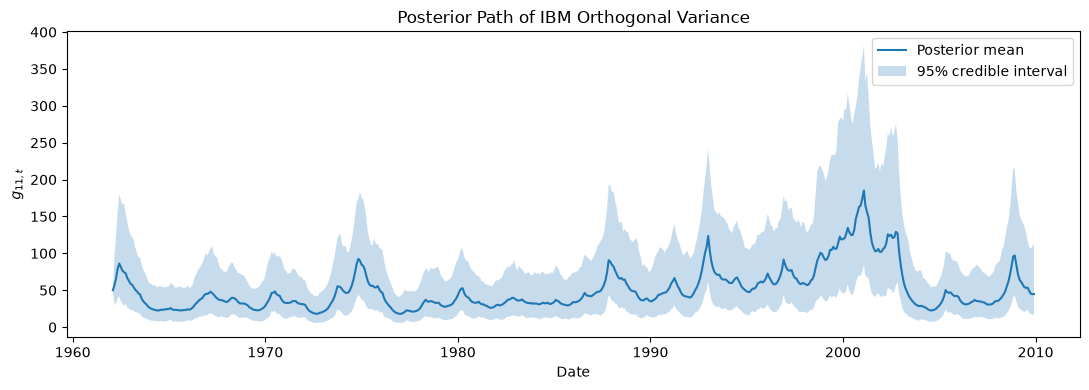

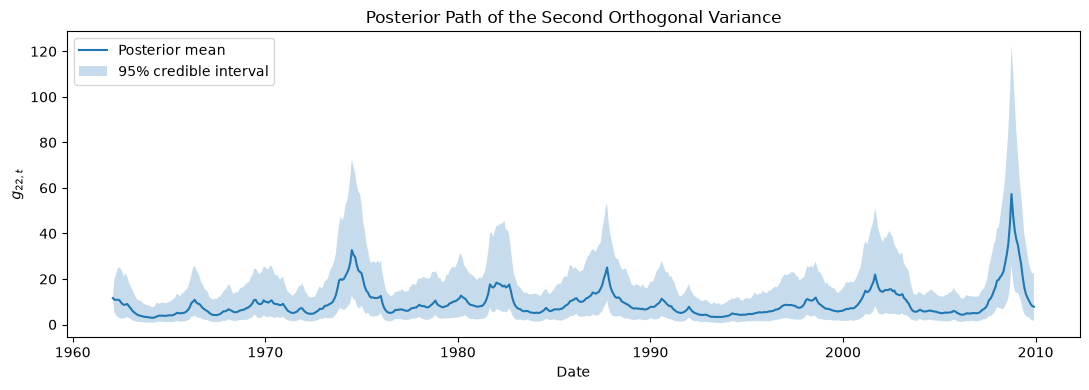

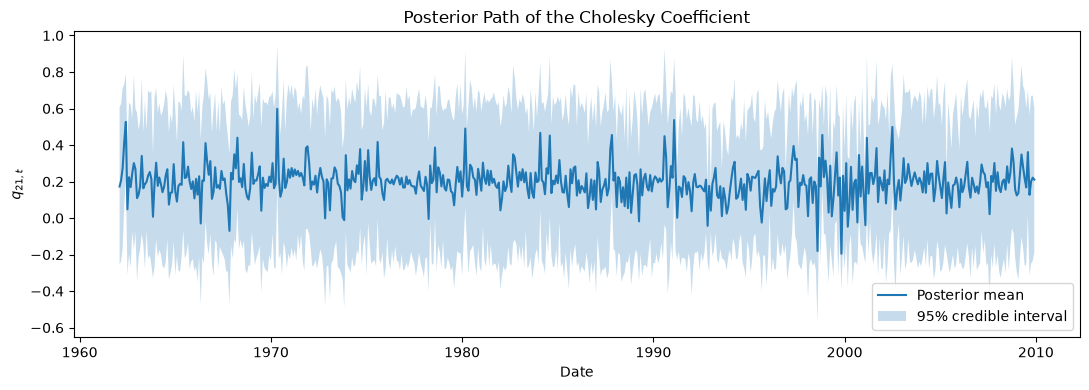

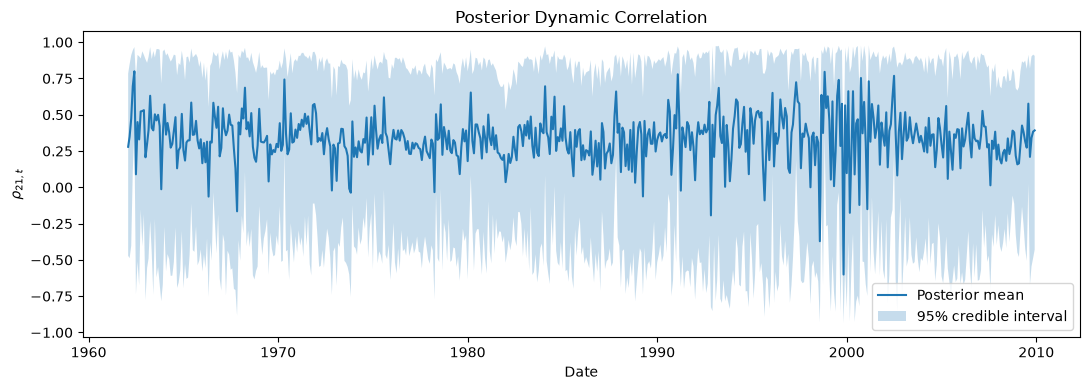

In [20]:
# ============================================================
# Posterior latent-path plots
# ============================================================

def plot_posterior_path(
    dates,
    mean_path,
    interval,
    title,
    ylabel,
):
    plt.figure(figsize=(11, 4))

    plt.plot(
        dates,
        mean_path,
        label="Posterior mean",
    )

    plt.fill_between(
        dates,
        interval[0],
        interval[1],
        alpha=0.25,
        label="95% credible interval",
    )

    plt.title(title)
    plt.xlabel("Date")
    plt.ylabel(ylabel)
    plt.legend()
    plt.tight_layout()
    plt.show()


plot_posterior_path(
    plot_dates,
    latent_posterior_means["g11"],
    latent_credible_intervals["g11"],
    "Posterior Path of IBM Orthogonal Variance",
    r"$g_{11,t}$",
)

plot_posterior_path(
    plot_dates,
    latent_posterior_means["g22"],
    latent_credible_intervals["g22"],
    "Posterior Path of the Second Orthogonal Variance",
    r"$g_{22,t}$",
)

plot_posterior_path(
    plot_dates,
    latent_posterior_means["q21"],
    latent_credible_intervals["q21"],
    "Posterior Path of the Cholesky Coefficient",
    r"$q_{21,t}$",
)

plot_posterior_path(
    plot_dates,
    latent_posterior_means["rho21"],
    latent_credible_intervals["rho21"],
    "Posterior Dynamic Correlation",
    r"$\rho_{21,t}$",
)


## Convergence comparison

The textbook compares posterior path means from chains of different retained lengths. The helper below runs a second chain and creates the corresponding \(y=x\) scatterplots.


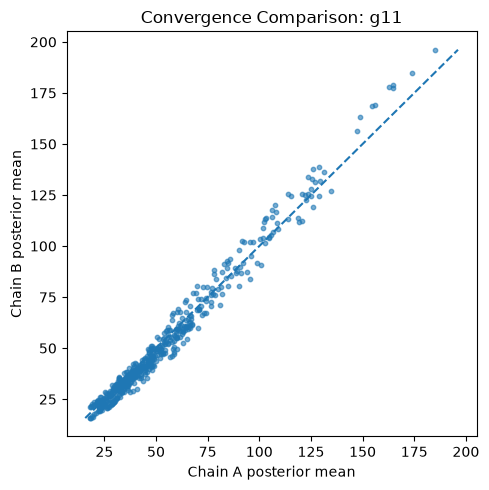

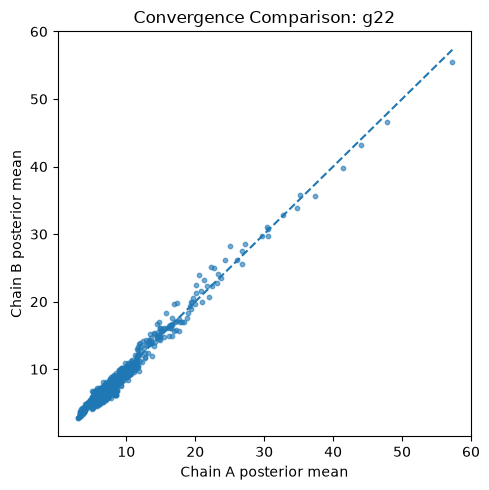

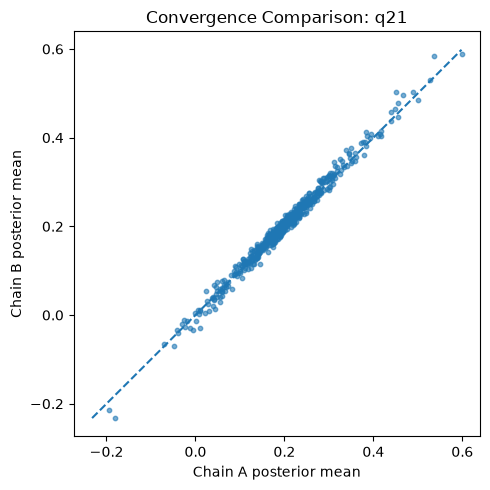

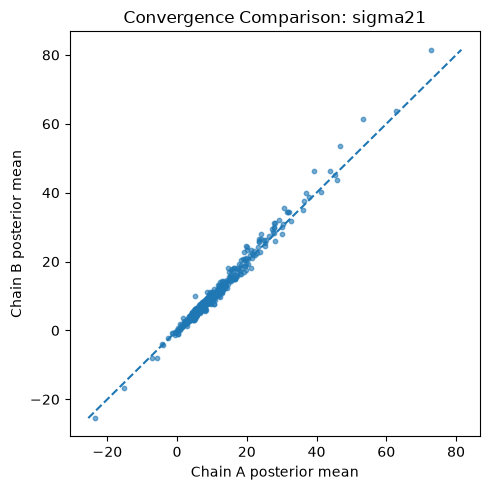

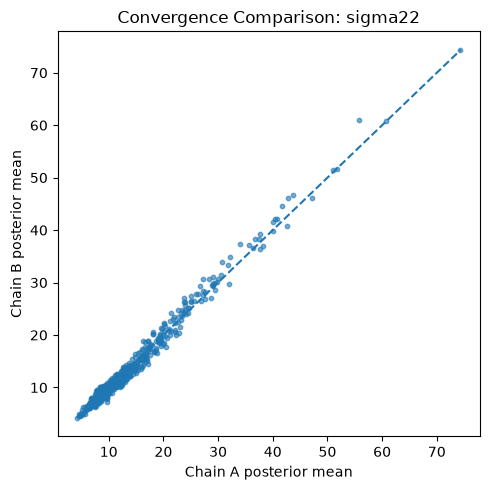

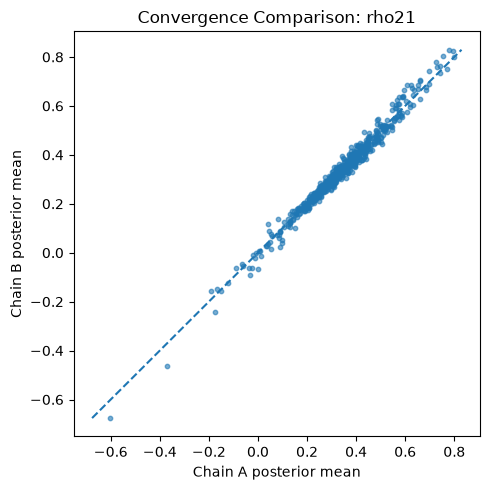

In [21]:
# ============================================================
# Textbook-style convergence comparison
# ============================================================

def retained_latent_means(history, burn_in):
    posterior = jax.tree_util.tree_map(
        lambda x: x[burn_in:],
        history,
    )

    g1 = jnp.exp(posterior.z1)
    g2 = jnp.exp(posterior.z2)
    q = posterior.q

    sigma11 = g1
    sigma21 = q * g1
    sigma22 = jnp.square(q) * g1 + g2
    rho21 = sigma21 / jnp.sqrt(sigma11 * sigma22)

    return {
        "g11": np.asarray(jnp.mean(g1, axis=0)),
        "g22": np.asarray(jnp.mean(g2, axis=0)),
        "q21": np.asarray(jnp.mean(q, axis=0)),
        "sigma21": np.asarray(jnp.mean(sigma21, axis=0)),
        "sigma22": np.asarray(jnp.mean(sigma22, axis=0)),
        "rho21": np.asarray(jnp.mean(rho21, axis=0)),
    }


def plot_chain_comparison(path_a, path_b, title):
    lower = min(np.min(path_a), np.min(path_b))
    upper = max(np.max(path_a), np.max(path_b))

    plt.figure(figsize=(5, 5))
    plt.scatter(path_a, path_b, s=10, alpha=0.6)
    plt.plot([lower, upper], [lower, upper], linestyle="--")
    plt.xlabel("Chain A posterior mean")
    plt.ylabel("Chain B posterior mean")
    plt.title(title)
    plt.tight_layout()
    plt.show()


# Chain B: 500 burn-in + 1000 retained iterations
comparison_key = jr.PRNGKey(987654)

_, _, comparison_history = run_gibbs_scan(
    initial_state=sv_init_state,
    initial_key=comparison_key,
    R=R_jax,
    priors=sv_priors,
    n_iter=1500,
)

chain_a_means = retained_latent_means(
    sv_history,
    burn_in=500,
)

chain_b_means = retained_latent_means(
    comparison_history,
    burn_in=500,
)

for variable in [
    "g11",
    "g22",
    "q21",
    "sigma21",
    "sigma22",
    "rho21",
]:
    plot_chain_comparison(
        chain_a_means[variable],
        chain_b_means[variable],
        title=f"Convergence Comparison: {variable}",
    )
